In [4]:

import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd




In [5]:

# root = os.getcwd()
folder = 'D:\\TIMA\\Nov24-May25-TIMA\\TIMA_output\\Report\\Report-2026-01-19'
file = 'mineral_count_nov24-may25.xlsx'
sheetname = 'mass' # 'resumed-rate'
df_orig = pd.read_excel(os.path.join(folder,file), sheet_name=sheetname)
df_orig


,phase,Phase,Si,Al,O,Na,K,Ca,Mg,Fe,...,5A-4-A,5A-5-A,5A-6-A,5A-2-B,5A-3-B,5A-4-B,5A-REF-1,5A-REF-2,5A-REF-4,5A-REF-5
0,Quartz,Quartz,47.0,0.0,53.0,0.0,0.0,0.0,0.0,0.0,...,13.732214,4.907255,3.450971,5.597065,5.216610,11.124809,1.886139,1.960069,9.549702,12.843562
1,Petalite LiAlSi4O10,Petalite,36.0,9.0,53.0,0.0,0.0,0.0,0.0,0.0,...,0.208981,0.037829,0.044753,0.037299,0.084555,0.163569,0.013419,0.012392,0.185281,0.193669
2,Albite,Albite,32.0,10.0,49.0,9.0,0.0,0.0,0.0,0.0,...,16.268052,5.046093,3.083550,5.447118,5.555641,13.253800,1.434350,1.534135,10.305414,13.492496
3,Spodumene LiAl[SiO3]2,Spodumene,30.0,15.0,52.0,0.0,0.0,0.0,0.0,0.0,...,2.500144,0.319457,0.328694,0.289992,0.797279,1.963904,0.105832,0.076594,1.742723,1.461909
4,Microcline/orthoclase,Microcline/orthoclase,30.0,10.0,46.0,0.0,14.0,0.0,0.0,0.0,...,6.013612,1.502873,0.978432,1.488861,2.015924,4.789268,0.395816,0.325522,4.054872,4.607072
5,Plagioclase,Plagioclase (Andesine),29.0,13.0,48.0,6.0,0.0,4.0,0.0,0.0,...,5.076539,6.280630,2.442923,6.929558,2.824425,3.804676,2.219996,1.731664,3.256980,5.185763
6,Enstatite,Enstatite,28.0,0.0,48.0,0.0,0.0,0.0,24.0,0.0,...,0.323462,0.431834,0.330678,0.310990,0.588080,0.134131,0.327143,0.232628,0.119548,0.148020
7,Actinolite,Actinolite,26.0,1.0,45.0,0.0,0.0,9.0,12.0,7.0,...,1.674039,4.237852,0.914280,5.424989,0.987005,1.405426,0.315063,0.248990,1.280038,1.859686
8,Diopside,Diopside,26.0,0.0,44.0,0.0,0.0,19.0,11.0,0.0,...,0.215136,0.618337,0.090002,0.562669,0.249000,0.155745,0.061721,0.041078,0.164505,0.144892
9,Kaolinite,Kaolinite,22.0,21.0,56.0,0.0,0.0,0.0,0.0,0.0,...,0.037730,0.011028,0.010987,0.009518,0.049515,0.037039,0.009910,0.011250,0.026298,0.029732


In [38]:
df = df_orig[df_orig['phase'] != 'Total'] 
df = df[df['phase'] != 'Copper'] 
df = df[['phase','5A-1-A',
       '5A-1-B', '5A-2-A', '5A-3-A', '5A-4-A', '5A-5-A', '5A-6-A', '5A-2-B',
       '5A-3-B', '5A-4-B', '5A-REF-1', '5A-REF-2', '5A-REF-4', '5A-REF-5']]
df = df.sort_values(by='5A-REF-1', ascending=False)
df = df.set_index('phase')
import matplotlib.colors as mcolors
# dict_colors = mcolors.CSS4_COLORS
# color_idx = {}
# for idx, color in enumerate(dict_colors.keys()):
#     color_idx[idx]  = color
# Assign a permanent color to each phase
dict_colors = list(mcolors.CSS4_COLORS.keys())

phase_colors = {
    phase: dict_colors[i]
    for i, phase in enumerate(df.index)
}

phase_colors

{'Unclassified': 'aliceblue',
 'Fiber': 'antiquewhite',
 'Plagioclase': 'aqua',
 'Biotite': 'aquamarine',
 'Quartz': 'azure',
 'Chlorite': 'beige',
 'Albite': 'bisque',
 'Amphibole': 'black',
 'Muscovite': 'blanchedalmond',
 'Microcline/orthoclase': 'blue',
 'Enstatite': 'blueviolet',
 'Actinolite': 'brown',
 'Epidote': 'burlywood',
 'Spodumene LiAl[SiO3]2': 'cadetblue',
 'Magnetite/Hematite/Goethite': 'chartreuse',
 'Corundum': 'chocolate',
 'Calcite': 'coral',
 'Diopside': 'cornflowerblue',
 'Titanite': 'cornsilk',
 'Iron metal': 'crimson',
 'Aluminum': 'cyan',
 'Pyrite/Pyrrhotite': 'darkblue',
 'Dolomite': 'darkcyan',
 'Apatite': 'darkgoldenrod',
 'The rest': 'darkgray',
 'Petalite LiAlSi4O10': 'darkgreen',
 'Rutile': 'darkgrey',
 'Kaolinite': 'darkkhaki',
 'Halite': 'darkmagenta',
 'Baryte': 'darkolivegreen',
 'Ilmenite': 'darkorange',
 'Bismuth': 'darkorchid',
 'Zircon': 'darkred',
 'Chalcopyrite': 'darksalmon',
 'Cadmium-bearing phase': 'darkseagreen',
 'Spessartine': 'darkslateb

In [39]:
df.columns

Index(['5A-1-A', '5A-1-B', '5A-2-A', '5A-3-A', '5A-4-A', '5A-5-A', '5A-6-A',
       '5A-2-B', '5A-3-B', '5A-4-B', '5A-REF-1', '5A-REF-2', '5A-REF-4',
       '5A-REF-5'],
      dtype='object')

In [40]:
# sample_name = '5A-1-A'

In [41]:
# sample_reorder = ['5A-1-A', '5A-1-B', 
# 					'5A-2-A', '5A-2-B',
# 					'5A-3-A', '5A-3-B',
# 					'5A-4-A',  '5A-4-B',
# 					'5A-5-A', '5A-6-A',
# 					'5A-REF-1', '5A-REF-2',
# 					'5A-REF-4', '5A-REF-5']

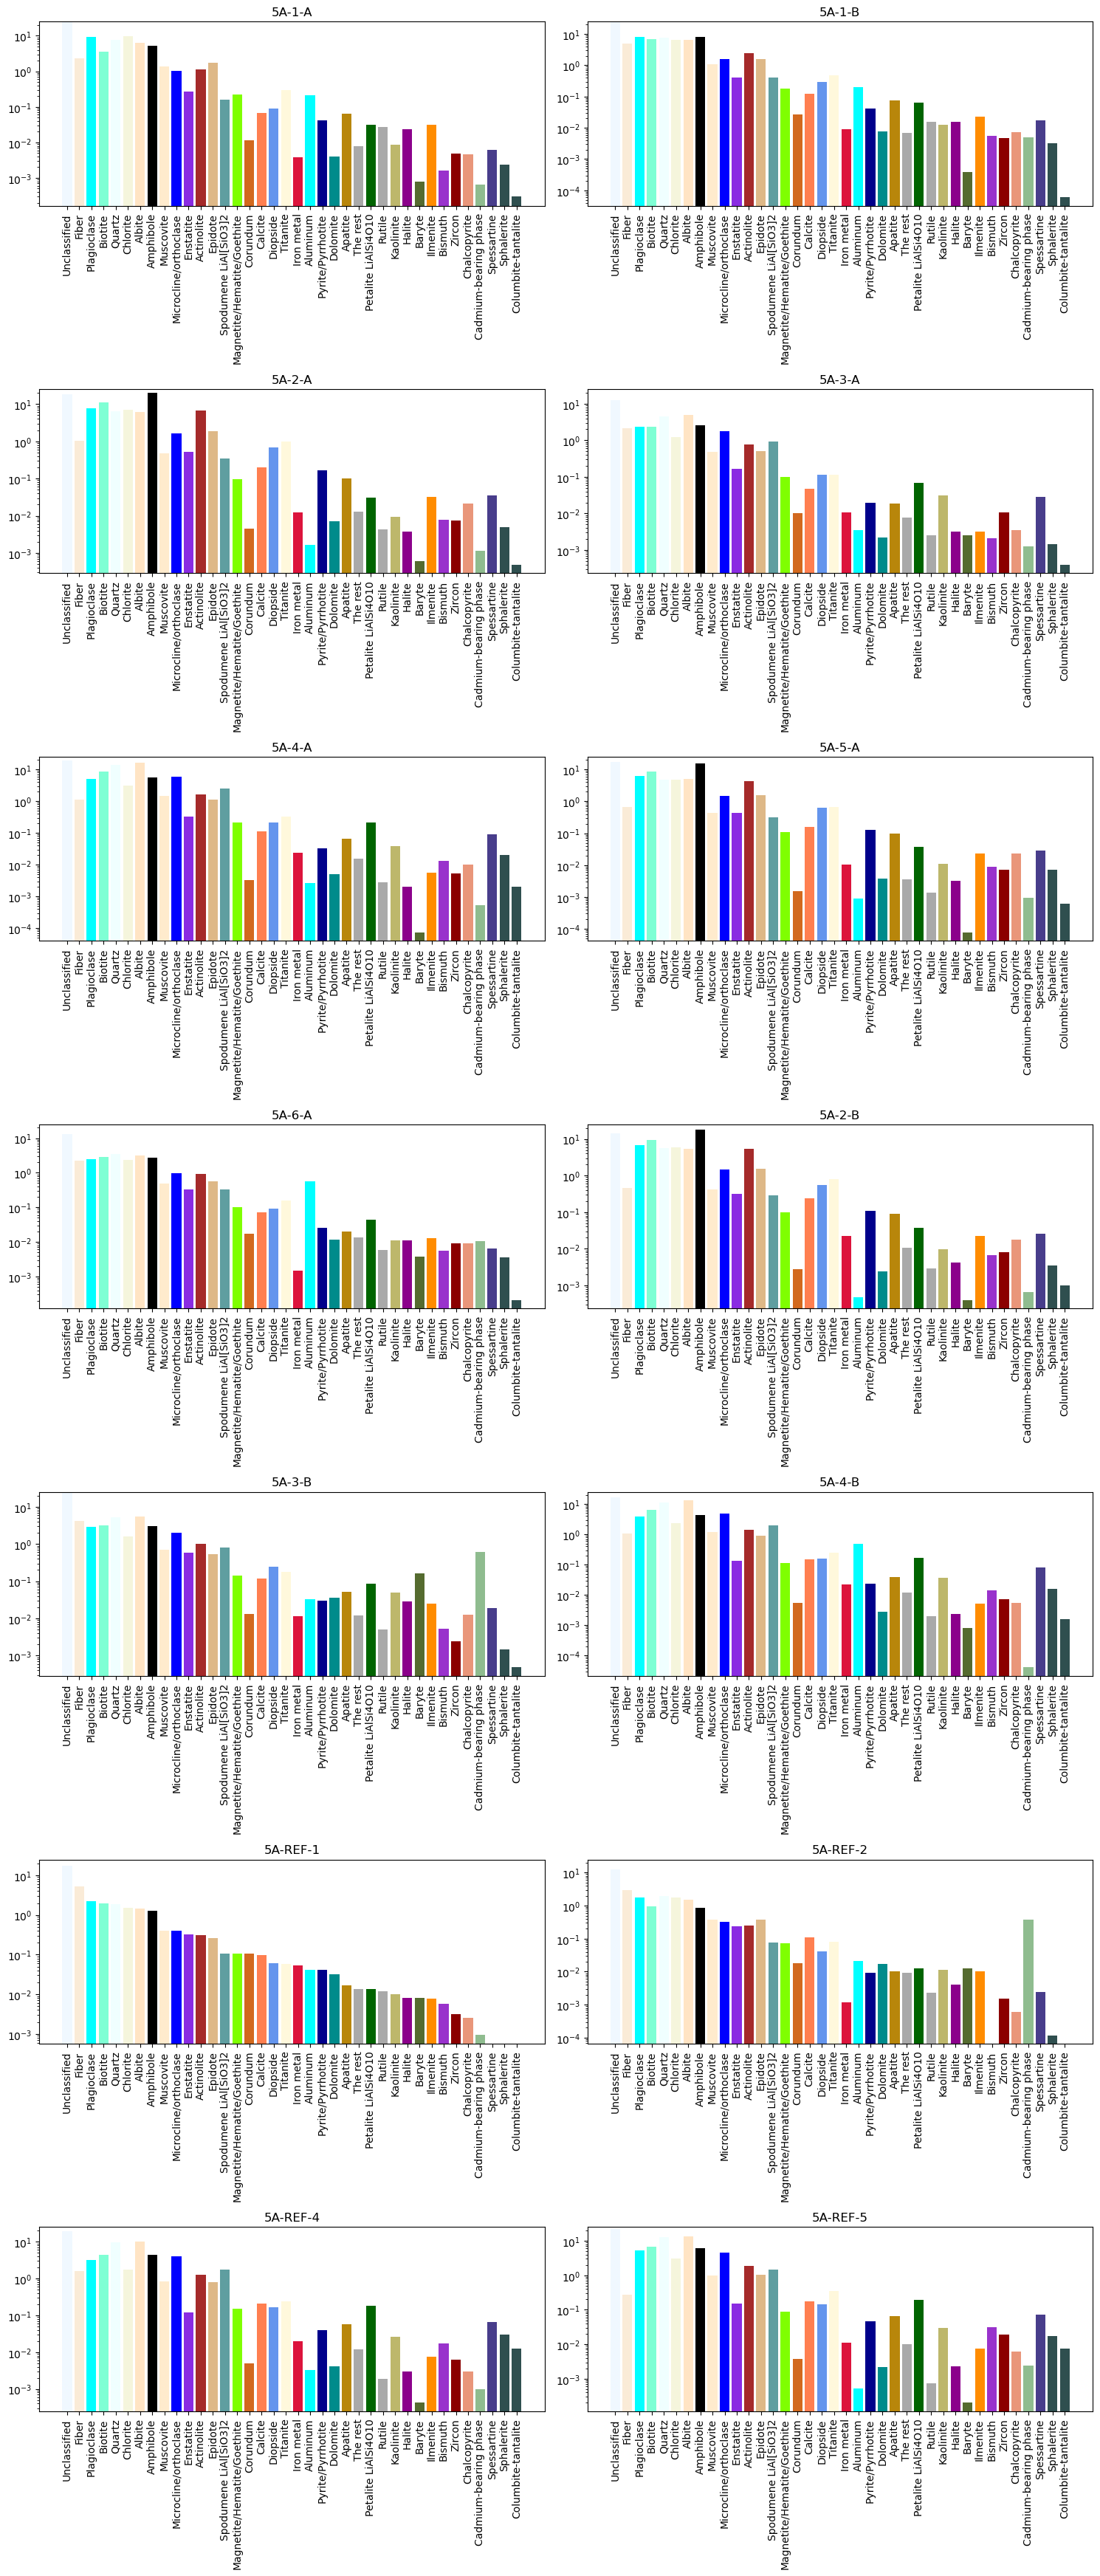

In [42]:
# import math

# samples = df.columns.tolist()
# n_cols = 2
# n_rows = math.ceil(len(samples) / n_cols)

# fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
# axes = axes.flatten()

# x = df.index

# for i, sample in enumerate(samples):
# 	ax = axes[i]
# 	ax.bar(x, df[sample], color= phase_colors[phase] )#[color_idx[j] for j in range(len(df.index))])
# 	ax.set_yscale('log')
# 	ax.set_xticks(range(len(x)))
# 	ax.set_xticklabels(x, rotation=90)
# 	ax.set_title(sample)
# 	ax.set_ylim(top=25)

# # Delete empty axes
# for j in range(len(samples), len(axes)):
# 	fig.delaxes(axes[j])

# plt.tight_layout()
# plt.show()

import math

samples = df.columns.tolist()
n_cols = 2
n_rows = math.ceil(len(samples) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()

x = df.index

# Get colors based on phase names
colors = [phase_colors[phase] for phase in x]

for i, sample in enumerate(samples):
    ax = axes[i]

    ax.bar(x, df[sample], color=colors)

    ax.set_yscale('log')
    ax.set_xticks(range(len(x)))
    ax.set_xticklabels(x, rotation=90)
    ax.set_title(sample)
    ax.set_ylim(top=25)

# Delete empty axes
for j in range(len(samples), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
resume_min = ['Fiber',
 'Plagioclase',
 'Biotite',
 'Quartz',
 'Chlorite',
 'Albite',
 'Amphibole',
 'Muscovite',
 'Microcline/orthoclase',
 'Enstatite',
 'Actinolite',
 'Epidote',
 'Spodumene LiAl[SiO3]2',
 'Pyrite/Pyrrhotite',
 'Apatite',
 'Petalite LiAlSi4O10',
 'Columbite-tantalite']

C:\Users\bruno\AppData\Local\Temp\ipykernel_16608\440873273.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_norm.columns, rotation=90)


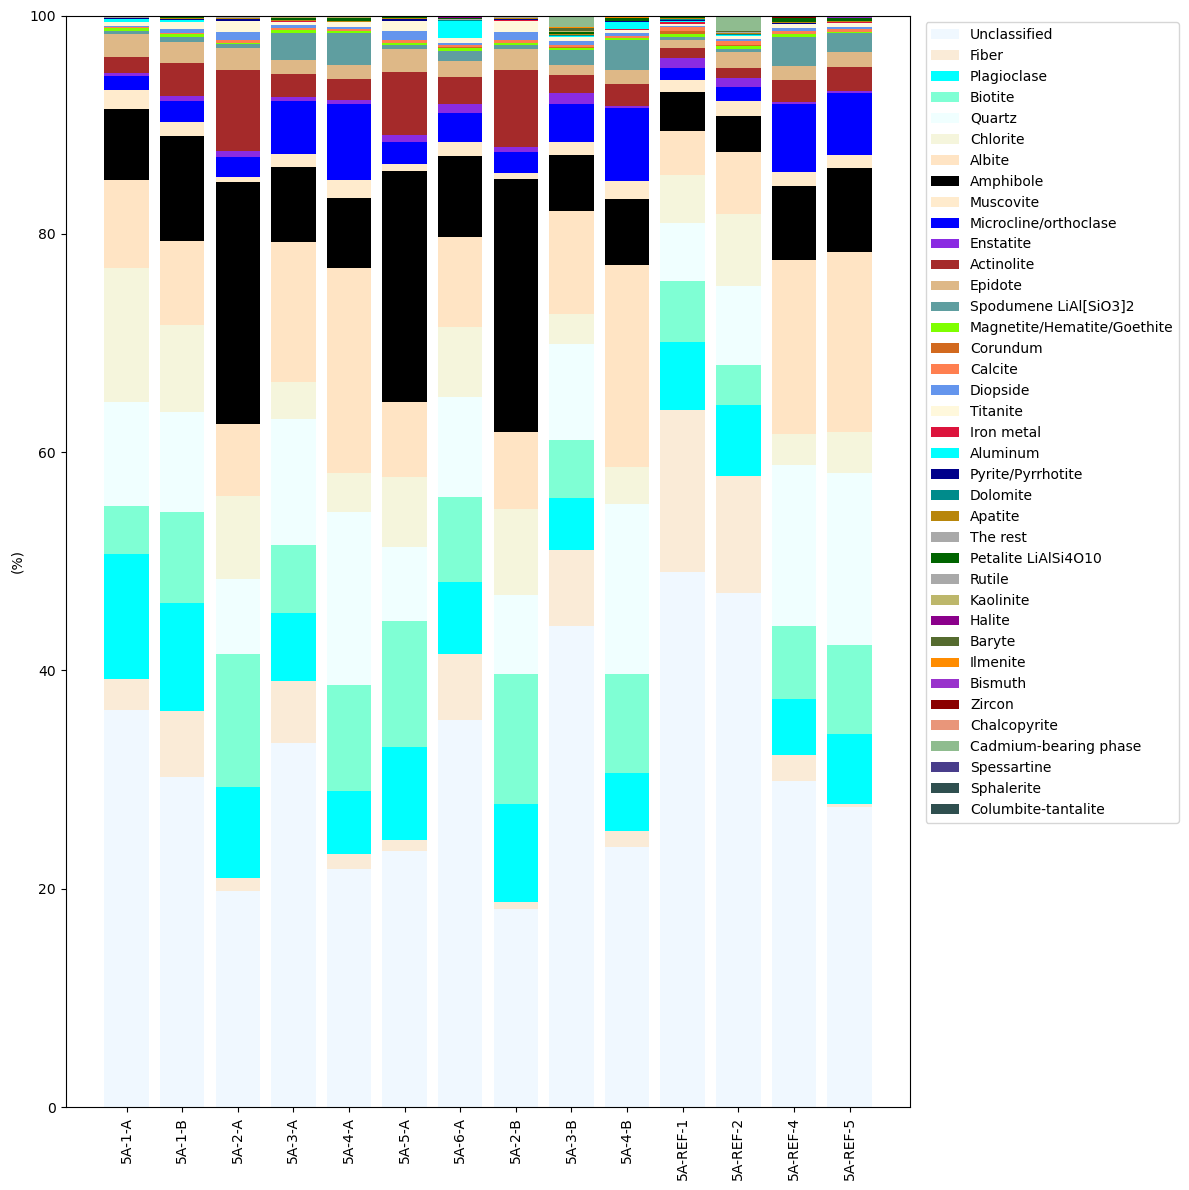

In [52]:
df_norm = df.div(df.sum(axis=0), axis=1) * 100




# fig, ax = plt.subplots(figsize=(12, 12))

# bottom = np.zeros(len(df_norm.columns))

# for i, phase in enumerate(df_norm.index):
#     ax.bar(df_norm.columns, df_norm.loc[phase, :], bottom=bottom,
#            color=color_idx[i], label=phase)
#     bottom += df_norm.loc[phase, :].values

# ax.set_xticklabels(df.columns, rotation=90)
# ax.set_ylabel("(%)")
# ax.set_ylim(0, 100)
# ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

# plt.tight_layout()
# plt.show()


# Plot
fig, ax = plt.subplots(figsize=(12, 12))

bottom = np.zeros(len(df_norm.columns))

for phase in df_norm.index:
    values = df_norm.loc[phase, :].values

    ax.bar(
        df_norm.columns,
        values,
        bottom=bottom,
        color=phase_colors[phase],
        label=phase
    )

    bottom += values

ax.set_xticklabels(df_norm.columns, rotation=90)
ax.set_ylabel("(%)")
ax.set_ylim(0, 100)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [53]:
exclude = ['Unclassified', 'The rest' ]
minerals = [m for m in list(df_norm.index) if m not in exclude]
# minerals

C:\Users\bruno\AppData\Local\Temp\ipykernel_16608\3949909008.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(df_norm_resumed.columns, rotation=90)


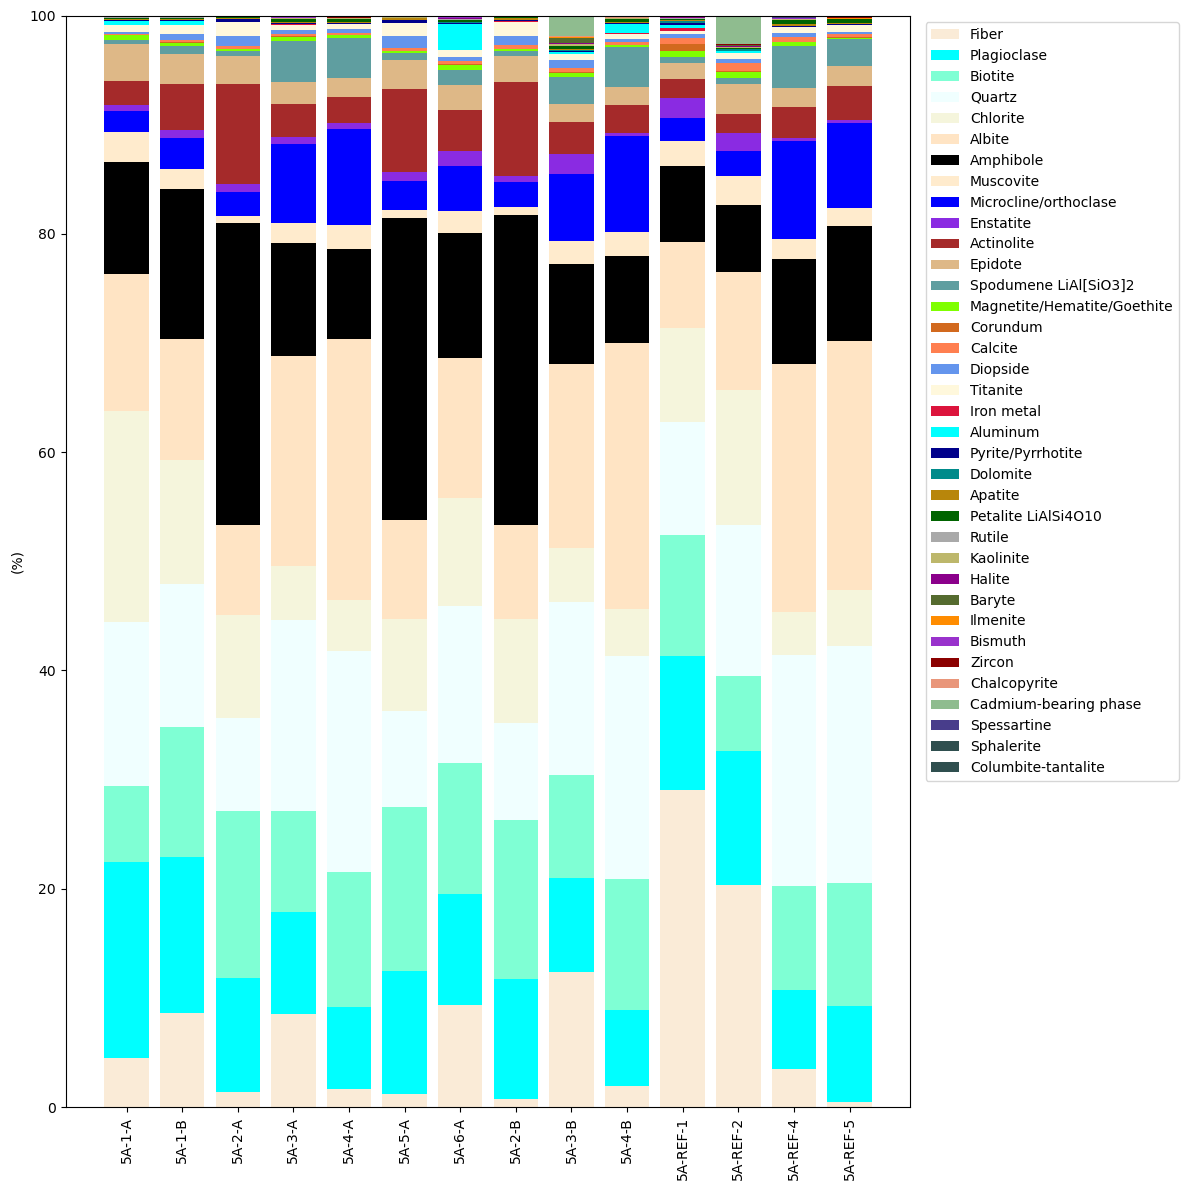

In [54]:

df_norm_resumed = df_norm.loc[minerals,:]

df_norm_resumed = df_norm_resumed.div(df_norm_resumed.sum(axis=0), axis=1) * 100
# Plot
fig, ax = plt.subplots(figsize=(12, 12))

bottom = np.zeros(len(df_norm_resumed.columns))

for phase in df_norm_resumed.index:
    values = df_norm_resumed.loc[phase, :].values

    ax.bar(
        df_norm_resumed.columns,
        values,
        bottom=bottom,
        color=phase_colors[phase],
        label=phase
    )

    bottom += values

ax.set_xticklabels(df_norm_resumed.columns, rotation=90)
ax.set_ylabel("(%)")
ax.set_ylim(0, 100)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

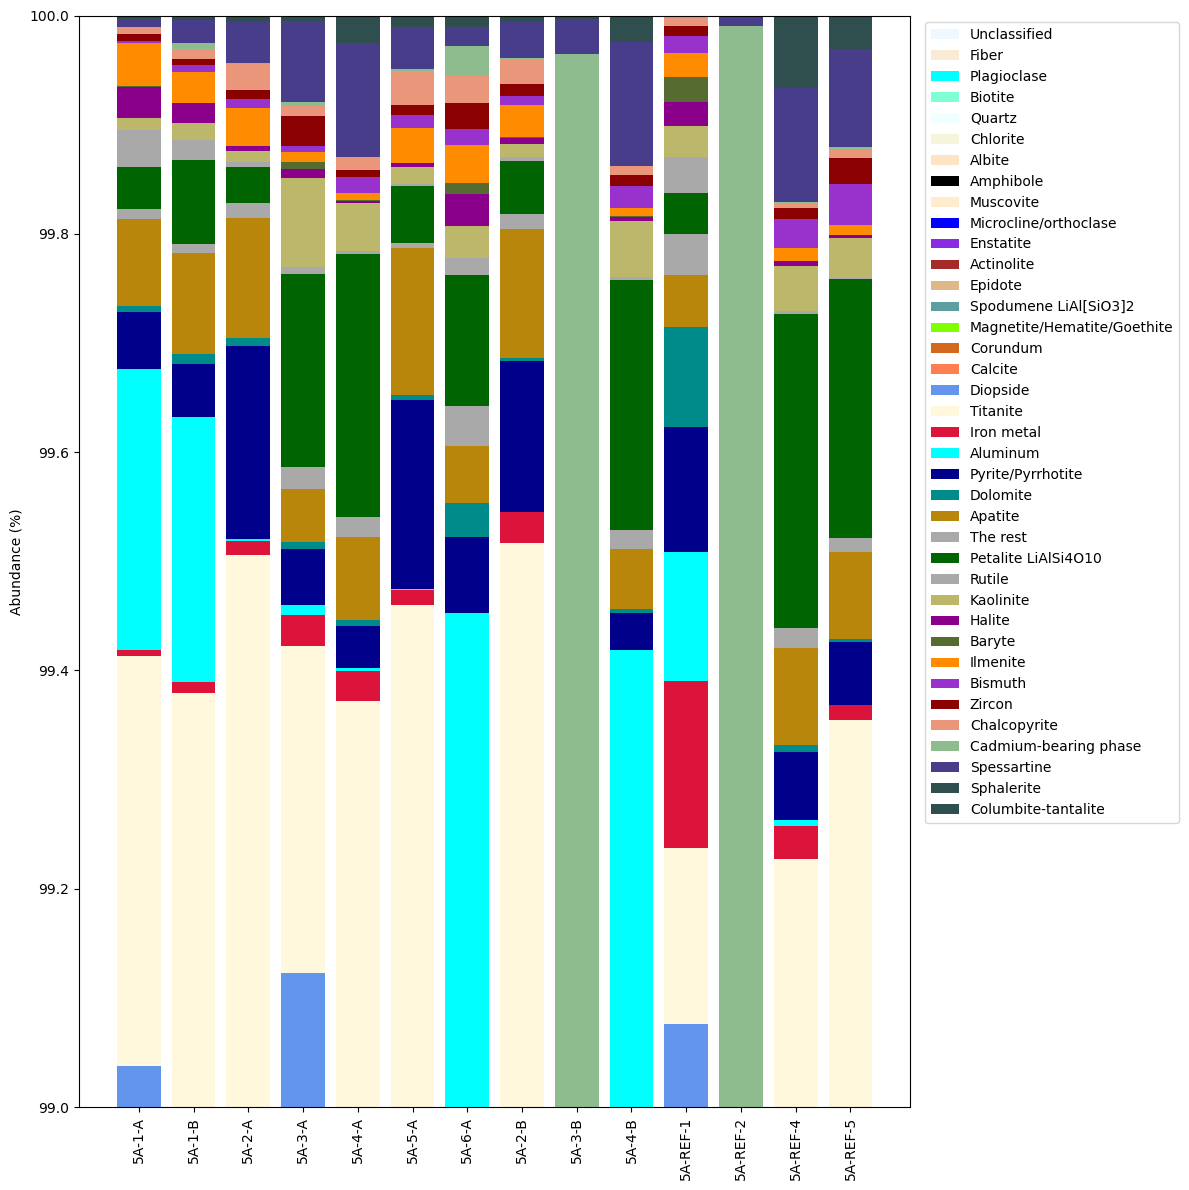

In [58]:
fig, ax = plt.subplots(figsize=(12, 12))

bottom = np.zeros(len(df_norm.columns))

for phase in df_norm.index:

    values = df_norm.loc[phase, :].values

    ax.bar(
        df_norm.columns,
        values,
        bottom=bottom,
        color=phase_colors.get(phase, 'grey'),
        label=phase
    )

    bottom += values

# Zoom into the upper 10%
ax.set_ylim(99, 100)

ax.set_ylabel("Abundance (%)")
ax.tick_params(axis='x', rotation=90)

ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()